# Iterative Workflow (Looping Workflow)

This is a workflow where two or more nodes keep looping until a certain condition becomes true.
You can think of it like a cycle that continues until you get the result you want.

## Real-World Example: Auto-Generate Tweets
To understand this workflow easily, let’s take a real example.
Imagine you are a busy person and don’t have time to write tweets every day.
So you create an AI agent that generates tweets for you automatically.

But sometimes the tweet it generates is not good enough.
Maybe:

It is too long
It is not clear
It does not match the topic
It needs improvement
So we create a loop:

**User → Tweet Generator → Evaluator → (Approve or Improve) → Tweet Generator → Evaluator … until approved**
You will also include a picture/diagram in your blog to show this workflow.

🔄 **How the Workflow Works**
Here’s what happens step-by-step:

1. **User gives a topic**
The user will enter a topic like:

“Benefits of AI in education”
“Healthy lifestyle tips”
“Motivation for students”
2. **Tweet Generator node**
This node generates a tweet/post based on the topic.

Example output:

`“AI is changing education by making learning faster and smarter.”`

3. **Tweet Evaluator node**
This node checks the generated tweet and gives feedback based on rules like:

* Is it clear?
* Is it short enough?
* Is it meaningful?
* Will it perform well on social media?
Evaluator also returns:

* status = approved
  or
* status = needs_improvement

4. **If status = approved → END**
Tweet is good → workflow stops.

5. **If status = needs_improvement → Go to Optimizer node**
Optimizer takes the evaluator feedback and creates a better, improved version of the tweet.

Then the improved tweet goes back to the Evaluator, and the loop continues until the evaluator approves it.

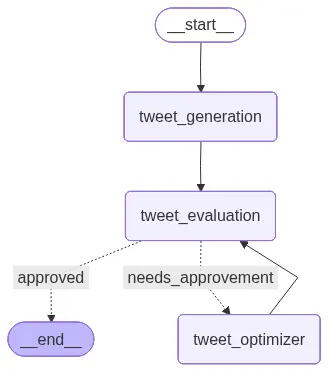


In [1]:
from langgraph.graph import StateGraph, START, END
from langchain_core.output_parsers import PydanticOutputParser
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_mistralai import ChatMistralAI
from typing import TypedDict, Annotated, Literal
from pydantic import Field,  BaseModel
from dotenv import load_dotenv
from langchain_core.messages import SystemMessage, HumanMessage
import operator
from langchain_groq import ChatGroq
from rich import print
import time




In [20]:
import os
from groq import Groq

In [21]:
client = Groq(api_key=os.getenv("GROQ_API_KEY"))
print([m.id for m in client.models.list().data])

[
    'qwen/qwen3.8-27b',
    'meta-llama/llama-prompt-guard-2-86m',
    'openai/gpt-oss-120b',
    'allam-2-7b',
    'canopylabs/orpheus-arabic-saudi',
    'whisper-large-v3-turbo',
    'openai/gpt-oss-20b',
    'canopylabs/orpheus-v1-english',
    'meta-llama/llama-prompt-guard-2-22m',
    'whisper-large-v3',
    'openai/gpt-oss-safeguard-20b'
]

In [22]:
load_dotenv(override=True)

True

In [23]:
# model = ChatGoogleGenerativeAI(model="gemini-3.5-flash")
# model = ChatMistralAI(model="mistral-small-latest", temperature=0.7)
model = ChatGroq(model="openai/gpt-oss-120b", max_retries=5)


In [24]:
class TweetState(TypedDict):
    topic: str
    tweet: str
    evaluation: Literal["approved", "needs_improvement"]
    feedback: str
    iteration: int
    max_iteration: int

    tweet_history: Annotated[list[str], operator.add]
    feedback_history: Annotated[list[str], operator.add]


In [25]:
class TweetEvaluationSchema(BaseModel):
    evaluation: Literal["approved", "needs_improvement"] = Field(..., description="Final evaluation result")
    feedback: str = Field(..., description="Constructive feedback for the tweet")

In [26]:
# create structured output llm
structured_evaluator_llm = model.with_structured_output(TweetEvaluationSchema)

In [27]:
def extract_text(content):
    if isinstance(content, str):
        return content

    if isinstance(content, list):
        return "\n".join(
            block["text"]
            for block in content
            if isinstance(block, dict) and block.get("type") == "text"
        )

    raise TypeError(f"Unexpected content type: {type(content)}")

In [28]:
def generate_tweet(state: TweetState):
    
    print("Generating tweet...")
    # prompt
    messages = [
        SystemMessage(content="You are a funny and clever Twitter/X influencer."),
        HumanMessage(content=f"""
Write a short, original, and hilarious tweet on the topic: "{state['topic']}".
Rules:
Do NOT use question-answer format.
Max 280 characters.
Use observational humor, irony, sarcasm, or cultural references.
Think in meme logic, punchlines, or relatable takes.
- Use simple, day to day english
"""),
]
    time.sleep(2)
    # send the generater_llm
    response = model.invoke(messages).content

    # return response
    return {'tweet': extract_text(response), 'tweet_history': [extract_text(response)]}



In [29]:
def evaluate_tweet(state: TweetState):

    print("Evaluating tweet...")
    print("Current iteration:", state["iteration"])
    # prompt
    messages = [
SystemMessage(content="You are a ruthless, no-laugh-given Twitter critic. You evaluate tweets based on humor, originality, virality, and tweet format."),
HumanMessage(content=f"""
Evaluate the following tweet:
Tweet: "{state['tweet']}"
Use the criteria below to evaluate the tweet:
1. Originality Is this fresh, or have you seen it a hundred times before?
2. Humor Did it genuinely make you smile, laugh, or chuckle?
3. Punchiness Is it short, sharp, and scroll-stopping?
4. Virality Potential Would people retweet or share it?
5. Format Is it a well-formed tweet (not a setup-punchline joke, not a Q&A joke, and under 280 characters)?
Auto-reject if:
It's written in question-answer format (e.g., "Why did..." or "What happens when...")
It exceeds 280 characters
It reads like a traditional setup-punchline joke
Dont end with generic, throwaway, or deflating lines that weaken the humor (e.g., "Masterpieces of the auntie-uncle universe" or vague summaries)
### Respond ONLY in structured format:
evaluation: "approved" or "needs improvement"
feedback: One paragraph explaining the strengths and weaknesses
""")
    ]
    time.sleep(2)
    # send to Evaluate_LLM
    response = structured_evaluator_llm.invoke(messages)

    # send response
    return {'evaluation': response.evaluation, 'feedback': response.feedback, 'feedback_history' : [response.feedback] }

In [30]:
def optimize_tweet(state: TweetState):

    print("Optimizing tweet...")

    # prompt
    messages = [
        SystemMessage(content="You punch up tweets for virality and humor based on given feedback."),
        HumanMessage(content=f"""
Improve the tweet based on this feedback:
"{state['feedback']}"
Topic: "{state ['topic']}"
Original Tweet:
{state['tweet']}
Re-write it as a short, viral-worthy tweet. Avoid Q&A style and stay under 280 characters."""),
]
    time.sleep(2)
    time.sleep(2)
    response = model.invoke(messages).content

    print("optimize response:\n",response)

    tweet = extract_text(response)

    iterator = state['iteration'] + 1

    return {'tweet': tweet, 'iteration': iterator, 'tweet_history': [tweet]}



In [31]:
def route_evaluation(state: TweetState):

    if state['evaluation'] == 'approved' or state['iteration'] >= state['max_iteration']:
        return 'approved'
    else:
        return 'needs_improvement'
    

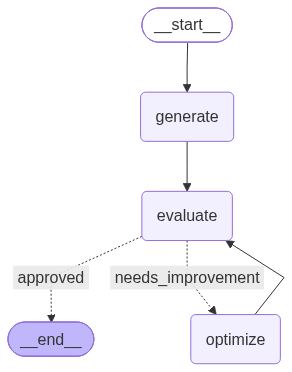

In [32]:
# define state for the graph
graph = StateGraph(TweetState)

# add nodes
graph.add_node('generate', generate_tweet)
graph.add_node('evaluate', evaluate_tweet)
graph.add_node('optimize', optimize_tweet)

# add edges
graph.add_edge(START, 'generate')
graph.add_edge('generate', 'evaluate')

graph.add_conditional_edges('evaluate', route_evaluation, {'approved':END, 'needs_improvement': 'optimize'})
graph.add_edge('optimize','evaluate')

workflow = graph.compile()

workflow


In [35]:
initial_state = {
    "topic": "It jobs in current swituations 2026",
    "iteration":1,
    "max_iteration":5
}

In [36]:
result = workflow.invoke(initial_state)

Generating tweet...

Evaluating tweet...

Current iteration: 1

Optimizing tweet...

optimize response:
 2026 IT job: junior dev who codes Rust, squashes quantum bugs, runs a multi‑cloud empire, and drafts commit msgs 
in emojis. Also, convince Grandma the server isn’t on a coffee break. ☕️🚀 #TechLife

Evaluating tweet...

Current iteration: 2

BadRequestError: Error code: 400 - {'error': {'message': 'Tool choice is required, but model did not call a tool', 'type': 'invalid_request_error', 'code': 'tool_use_failed', 'failed_generation': 'evaluation: "approved"\nfeedback: "The tweet nails tech‑savvy originality by blending futuristic jargon (Rust, quantum bugs, multi‑cloud empire) with a relatable, absurd twist of convincing Grandma about the server, which lands a solid chuckle. Its humor is crisp without resorting to a classic setup‑punchline, and the emoji and #TechLife tag add visual punch and shareability. At roughly 180 characters it stays well within the limit, and the concise list format makes it scroll‑stopping. A minor tweak could trim a word or two for even tighter punch, but overall it’s a strong, retweet‑worthy slice of tech culture."'}}